# 06.6 · PCA: fewer dimensions, same story

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cloudops-one/training-ai-ml/blob/main/modules/06-unsupervised/06-pca/lesson.ipynb)

Read the [README](README.md) first and do the 5-point calculation on paper. This notebook repeats it in NumPy, then uses PCA on handwritten digits and on ShopWave's customers.

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore")

## 1. The curse of dimensionality, in one experiment

Scatter 500 random points in a cube with *d* sides, and look at one point's distances to all the others. In 2-D the nearest point is much nearer than the farthest. As *d* grows, every point ends up at roughly the same distance from every other, so "nearest neighbour" stops meaning anything.

In [2]:
rng = np.random.default_rng(0)
for d in [2, 10, 100, 1000]:
    pts = rng.random((500, d))
    dist = np.linalg.norm(pts[1:] - pts[0], axis=1)
    print(f"d = {d:>4}:  nearest {dist.min():6.2f}   farthest {dist.max():6.2f}   "
          f"farthest / nearest = {dist.max() / dist.min():5.1f}")

d =    2:  nearest   0.01   farthest   0.94   farthest / nearest =  67.1
d =   10:  nearest   0.58   farthest   1.92   farthest / nearest =   3.3
d =  100:  nearest   3.63   farthest   4.95   farthest / nearest =   1.4
d = 1000:  nearest  12.29   farthest  13.62   farthest / nearest =   1.1


The ratio collapses towards 1. Distance-based methods (KNN, K-Means, DBSCAN) suffer first. One fix is to keep only the few directions that carry most of the information: that is PCA.

## 2. The five customers, by hand

The same numbers as the README. Each step prints the value you wrote on paper.

In [3]:
P = np.array([[2, 1], [3, 3], [4, 3], [5, 5], [6, 8]], dtype=float)   # 5 customers, 2 features

mean = P.mean(axis=0)
Pc = P - mean                                  # step 1: centre
print("mean:", mean)
print("centred points:\n", Pc)

mean: [4. 4.]
centred points:
 [[-2. -3.]
 [-1. -1.]
 [ 0. -1.]
 [ 1.  1.]
 [ 2.  4.]]


In [4]:
C = Pc.T @ Pc / (len(P) - 1)                   # step 2: covariance matrix (n - 1)
print("covariance matrix:\n", C)
print("same as np.cov:", np.allclose(C, np.cov(P, rowvar=False)))

covariance matrix:
 [[2.5 4. ]
 [4.  7. ]]
same as np.cov: True


In [5]:
eigenvalues, eigenvectors = np.linalg.eigh(C)  # step 3: eigh returns them smallest first
order = np.argsort(eigenvalues)[::-1]
eigenvalues, eigenvectors = eigenvalues[order], eigenvectors[:, order]
pc1 = eigenvectors[:, 0] * np.sign(eigenvectors[0, 0])   # make the first entry positive
print("eigenvalues:", eigenvalues.round(3))
print("PC1 direction:", pc1.round(3))
print("explained variance ratio:", (eigenvalues / eigenvalues.sum()).round(3))

eigenvalues: [9.339 0.161]
PC1 direction: [0.505 0.863]
explained variance ratio: [0.983 0.017]


In [6]:
scores = Pc @ pc1                              # step 4: project onto PC1
print("PC1 scores:", scores.round(2))
print("variance of the scores:", scores.var(ddof=1).round(3), "= the first eigenvalue")

PC1 scores: [-3.6  -1.37 -0.86  1.37  4.46]
variance of the scores: 9.339 = the first eigenvalue


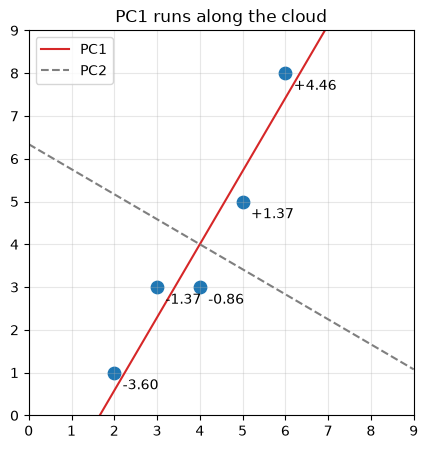

In [7]:
plt.figure(figsize=(5, 5))
plt.scatter(P[:, 0], P[:, 1], s=80)
plt.axline(mean, mean + pc1, color="tab:red", label="PC1")
plt.axline(mean, mean + eigenvectors[:, 1], color="tab:gray", linestyle="--", label="PC2")
for (x, y_), s in zip(P, scores):
    plt.annotate(f"{s:+.2f}", (x, y_), textcoords="offset points", xytext=(6, -12))
plt.gca().set_aspect("equal"); plt.xlim(0, 9); plt.ylim(0, 9)
plt.legend(); plt.grid(alpha=.3); plt.title("PC1 runs along the cloud"); plt.show()

## 3. scikit-learn

`PCA` centres the data, finds the components and projects, in one call. The sign of a component is arbitrary, so sklearn may flip it; the numbers are otherwise identical.

In [8]:
from sklearn.decomposition import PCA
pca = PCA().fit(P)
print("components:\n", pca.components_.round(3))
print("explained_variance_:", pca.explained_variance_.round(3))
print("explained_variance_ratio_:", pca.explained_variance_ratio_.round(3))
print("scores:", pca.transform(P)[:, 0].round(2))

components:
 [[ 0.505  0.863]
 [ 0.863 -0.505]]
explained_variance_: [9.339 0.161]
explained_variance_ratio_: [0.983 0.017]
scores: [-3.6  -1.37 -0.86  1.37  4.46]


## 4. 64 dimensions: handwritten digits

Each digit is an 8×8 image, so 64 pixel features. How many directions do we really need?

In [9]:
from sklearn.datasets import load_digits
X_dig, y_dig = load_digits(return_X_y=True)
pca_dig = PCA().fit(X_dig)
ratio = pca_dig.explained_variance_ratio_
cum = np.cumsum(ratio)
print("first five components:", ratio[:5].round(3))
for target in [0.80, 0.90, 0.95]:
    print(f"components needed for {target:.0%} of the variance: {np.argmax(cum >= target) + 1}")

first five components: [0.149 0.136 0.118 0.084 0.058]
components needed for 80% of the variance: 13
components needed for 90% of the variance: 21
components needed for 95% of the variance: 29


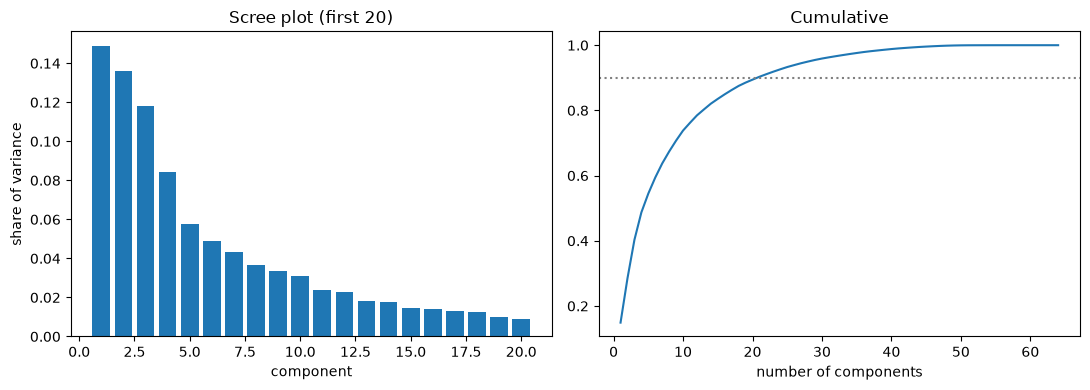

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].bar(range(1, 21), ratio[:20]); ax[0].set_title("Scree plot (first 20)")
ax[0].set_xlabel("component"); ax[0].set_ylabel("share of variance")
ax[1].plot(range(1, 65), cum); ax[1].axhline(0.9, color="gray", linestyle=":")
ax[1].set_title("Cumulative"); ax[1].set_xlabel("number of components")
plt.tight_layout(); plt.show()

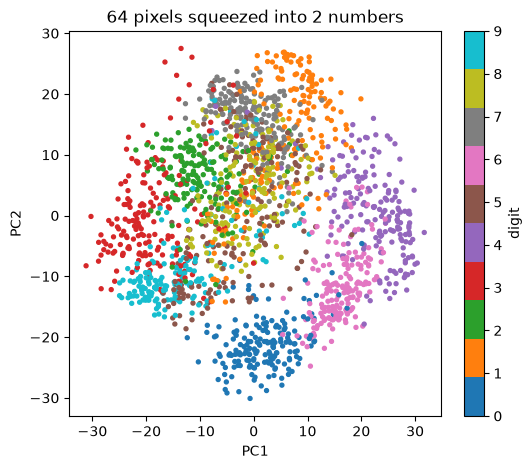

In [11]:
two = PCA(n_components=2).fit_transform(X_dig)
plt.figure(figsize=(6, 5))
sc = plt.scatter(two[:, 0], two[:, 1], c=y_dig, cmap="tab10", s=8)
plt.colorbar(sc, label="digit"); plt.xlabel("PC1"); plt.ylabel("PC2")
plt.title("64 pixels squeezed into 2 numbers"); plt.show()

Two components keep only about 29% of the variance, yet 0s, 4s and 6s already form their own regions. Others overlap: two numbers are not enough to tell every digit apart.

## 5. PCA as a preprocessing step

Put PCA inside a pipeline before a classifier and vary the number of components. Cross-validation tells us how much information each extra direction adds.

In [12]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score

for k in [2, 5, 10, 20, 40, 64]:
    pipe = make_pipeline(StandardScaler(), PCA(n_components=k), LogisticRegression(max_iter=2000))
    acc = cross_val_score(pipe, X_dig, y_dig, cv=5).mean()
    print(f"{k:>2} components: CV accuracy {acc:.3f}")

 2 components: CV accuracy 0.535
 5 components: CV accuracy 0.771
10 components: CV accuracy 0.840
20 components: CV accuracy 0.899
40 components: CV accuracy 0.914


64 components: CV accuracy 0.920


Accuracy climbs fast and then flattens: 20 components get within about 2 points of all 64. PCA is fitted inside each fold, so there is no leakage (Module 04).

## 6. Scale first, or PCA just finds your biggest unit

ShopWave's RFM table: recency in days, frequency in orders, monetary in pounds.

In [13]:
# --- data helper: works locally and on Colab -------------------------------
from pathlib import Path
import urllib.request

def data_path(name):
    """Return a local path to data/<name>, downloading from GitHub on Colab."""
    for parent in [Path.cwd(), *Path.cwd().parents]:
        candidate = parent / "data" / name
        if candidate.exists():
            return candidate
    url = f"https://raw.githubusercontent.com/cloudops-one/training-ai-ml/main/data/{name}"
    dest = Path(name)
    if not dest.exists():
        urllib.request.urlretrieve(url, dest)
    return dest

import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore")

import sys
sys.path.insert(0, str(data_path("download.py").parent))
from download import load_retail

raw = load_retail("Year 2010-2011")
sales = raw[~raw["Invoice"].astype(str).str.startswith("C")]
sales = sales[(sales["Quantity"] > 0) & (sales["Price"] > 0)].dropna(subset=["Customer ID"]).drop_duplicates()
sales = sales.assign(Revenue=sales["Quantity"] * sales["Price"], **{"Customer ID": sales["Customer ID"].astype(int)})
print(f"{len(sales):,} clean transaction lines, {sales['Customer ID'].nunique():,} customers")

392,693 clean transaction lines, 4,338 customers


In [14]:
from sklearn.preprocessing import StandardScaler

snapshot = pd.Timestamp("2011-12-10")
rfm = sales.groupby("Customer ID").agg(
    recency=("InvoiceDate", lambda d: (snapshot - d.max()).days),
    frequency=("Invoice", "nunique"),
    monetary=("Revenue", "sum"))
rfm_scaled = pd.DataFrame(StandardScaler().fit_transform(np.log1p(rfm)), index=rfm.index, columns=rfm.columns)
print(f"{len(rfm):,} customers")
rfm.describe().round(1)

4,338 customers


,recency,frequency,monetary
count,4338.0,4338.0,4338.0
mean,92.1,4.3,2048.7
std,100.0,7.7,8985.2
min,0.0,1.0,3.8
25%,17.0,1.0,306.5
50%,50.0,2.0,668.6
75%,141.8,5.0,1660.6
max,373.0,209.0,280206.0


In [15]:
for name, data in [("raw", rfm), ("log + scaled", rfm_scaled)]:
    p = PCA().fit(data)
    print(f"{name:>13}: variance ratio {p.explained_variance_ratio_.round(3)}")
    print(f"{'':>13}  PC1 weights (R, F, M) {p.components_[0].round(2)}")

          raw: variance ratio [1. 0. 0.]
               PC1 weights (R, F, M) [-0.  0.  1.]
 log + scaled: variance ratio [0.752 0.187 0.061]
               PC1 weights (R, F, M) [-0.51  0.62  0.6 ]


On the raw table PC1 is simply "monetary": pounds vary in the thousands, days in the hundreds, orders in single digits, so pounds swamp the covariance. After log + scaling, PC1 mixes all three: high frequency and spend, low recency. That is a "customer value" axis. PC1 alone keeps about three-quarters of the variance.

## 7. A 2-D picture of customer segments

K-Means (lesson 06.2) on the three scaled RFM columns, then PCA only for drawing.

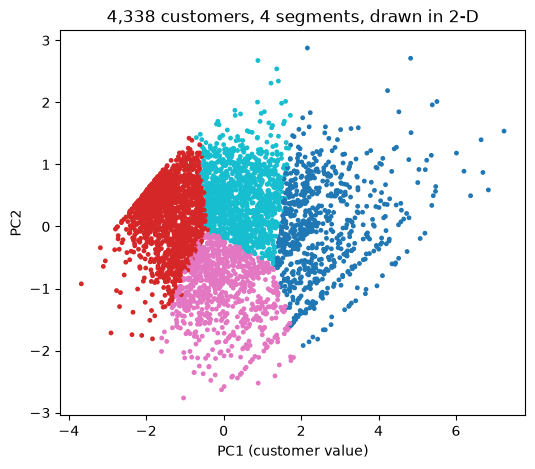

         recency  frequency  monetary
segment                              
0            8.0       10.0    3750.0
1          173.0        1.0     297.0
2           16.0        2.0     480.0
3           54.0        4.0    1352.0


In [16]:
from sklearn.cluster import KMeans
labels = KMeans(n_clusters=4, n_init=10, random_state=42).fit_predict(rfm_scaled)
xy = PCA(n_components=2).fit_transform(rfm_scaled)
plt.figure(figsize=(6, 5))
plt.scatter(xy[:, 0], xy[:, 1], c=labels, cmap="tab10", s=6)
plt.xlabel("PC1 (customer value)"); plt.ylabel("PC2")
plt.title("4,338 customers, 4 segments, drawn in 2-D"); plt.show()
print(rfm.assign(segment=labels).groupby("segment").median().round(0))

The segments line up mostly along PC1, which matches the "value" reading above. This is the most common everyday use of PCA: making a picture of data that has more than two columns.

## Quiz answers

1. In many dimensions every point is about the same distance from every other, so distances (and the methods built on them) lose meaning; also, data becomes sparse and models need far more rows.
2. The direction along which the centred data has the largest variance. The second component is the largest-variance direction at right angles to the first, and so on.
3. Because PCA maximises variance, and variance depends on units: a column in pounds has a far larger variance than one in orders, so it dominates PC1 without being more important.
4. 9.339 / (9.339 + 0.161) = 0.983, about 98%.
5. When you need the original features to explain the model; when the important signal has low variance (PCA keeps spread, not predictive power); when relationships are non-linear; when you have few columns already.

**Next:** [06.7 t-SNE and UMAP](../07-tsne-umap/) (optional), or [06.8 Anomaly detection](../08-anomaly-detection/).